# Exploratory retention prioritization

Simulate equal-cost review capacity at **20% (primary)**, with **10% and 30% sensitivity checks**. Compare repeated random selection, risk-only, proxy-only and risk × proxy rankings. This evaluates retrospective capture of observed resignations, not prevention, real employee worth or financial return.

No final predictive model or calibrated probability source is frozen. The numerical development AP leader is therefore used only as an **exploratory raw-score source**. The risk × proxy score is not a calibrated expected-benefit estimate. Run All reads validated development evidence and exports aggregates without accessing holdout features or labels.

## 1. Setup and canonical predictions

Preserve original development class imbalance. Validate the six registered OOF files before selecting the descriptive pooled-AP leader. Recompute AP from the inputs rather than trusting a potentially stale comparison export.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Find the project from either its root or this notebook's directory.
ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / "configs/analysis_registry.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.inputs import load_group_inputs, load_development_data
from src.evaluation.metrics import calculate_binary_metrics
from src.data.feature_contract import load_feature_contract

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
contract = load_feature_contract(ROOT / "configs/feature_contract.yaml")

In [2]:
# Validate IDs, source labels, frozen fold assignments and probability ranges.
# EBM additionally verifies the formal artifact manifest. No fallback is used.
registry, frames = load_group_inputs(ROOT)
expected_models = {"FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"}
if set(frames) != expected_models:
    raise ValueError("Exactly the six canonical headline models are required.")
reference = next(iter(frames.values()))
for model, frame in frames.items():
    if not np.array_equal(frame.Employee_ID, reference.Employee_ID):
        raise ValueError(f"{model}: development IDs are not aligned.")
    if not np.array_equal(frame.y_true, reference.y_true):
        raise ValueError(f"{model}: development targets are not aligned.")
prevalence = float(reference.y_true.mean())
display(pd.DataFrame([{"model": name, "rows": len(frame), "folds": frame.cv_fold.nunique(),
                       "input": registry["models"][name]["oof_path"]}
                      for name, frame in frames.items()]))
display(reference.y_true.value_counts().sort_index().rename_axis("Resigned").to_frame("rows"))
print(f"Positive prevalence: {prevalence:.2%}. Original class imbalance retained; no resampling or training here.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,model,rows,folds,input
0,FT-Transformer,80000,5,results/models/ft_transformer/strict_nested/oo...
1,CatBoost,80000,5,results/models/catboost/oof_predictions.csv
2,XGBoost,80000,5,results/models/xgboost/oof_predictions.csv
3,LightGBM,80000,5,results/models/lightgbm/strict_nested/oof_pred...
4,EBM,80000,5,results/models/ebm/individual_IT25100429/oof_p...
5,TabNet,80000,5,results/models/tabnet/oof_predictions.csv


,rows
Resigned,
0,71992
1,8008


Positive prevalence: 10.01%. Original class imbalance retained; no resampling or training here.


In [3]:
from sklearn.preprocessing import MinMaxScaler
from src.prioritization.ranking import evaluate_ranking, select_top_k

model_scores = pd.DataFrame([{"model": model,
                             "pooled_average_precision": calculate_binary_metrics(frame.y_true, frame.y_probability)["average_precision"]}
                            for model, frame in frames.items()]).sort_values(
                                ["pooled_average_precision", "model"], ascending=[False, True])
leader = str(model_scores.iloc[0].model)
display(model_scores.reset_index(drop=True))
print(f"Exploratory raw risk source: {leader}; it is not a frozen deployment model.")

,model,pooled_average_precision
0,XGBoost,0.101181
1,LightGBM,0.100153
2,TabNet,0.099965
3,CatBoost,0.099860
4,EBM,0.099000
5,FT-Transformer,0.098648


Exploratory raw risk source: XGBoost; it is not a frozen deployment model.


## 2. Development-only value proxies

The approved primary proxy averages normalized Performance_Score, Monthly_Salary and Years_At_Company with equal weights. Salary units are unverified and salary is deterministically related to title/performance in the audit; this proxy is an illustrative score, never measured employee worth.

Fit each MinMaxScaler on the applicable **outer-training development rows**, then transform that fold's validation rows. This prevents validation observations from setting their own normalization bounds. Values beyond training bounds are clipped to [0, 1]; the number clipped is reported. Constant training features map to zero. No rows or labels select a proxy formula.

Also report two predeclared sensitivity proxies: the no-salary mean of normalized performance and tenure, and the product of epsilon-adjusted components. Here epsilon = 0.01 and each component becomes `epsilon + (1 − epsilon) × normalized value`; this explicitly stated illustrative choice avoids automatic zeroing at zero tenure. Sensitivity results do not replace the primary proxy or select a new policy.

In [4]:
COMPONENTS = ["Performance_Score", "Monthly_Salary", "Years_At_Company"]
dev, split = load_development_data(ROOT, usecols=COMPONENTS)
risk = frames[leader][["Employee_ID", "cv_fold", "y_true", "y_probability"]].merge(
    dev[["Employee_ID", *COMPONENTS]], on="Employee_ID", how="left", validate="one_to_one", indicator=True)
assert len(risk) == len(reference) and risk["_merge"].eq("both").all()
if not np.isfinite(risk[COMPONENTS].to_numpy(dtype=float)).all():
    raise ValueError("Proxy components must be finite.")
normalized = pd.DataFrame(index=risk.index, columns=COMPONENTS, dtype=float)
bounds_rows = []
for fold in sorted(risk.cv_fold.unique()):
    validation = risk.cv_fold.eq(fold)
    training = ~validation
    scaler = MinMaxScaler(clip=True).fit(risk.loc[training, COMPONENTS])
    transformed = scaler.transform(risk.loc[validation, COMPONENTS])
    # A constant training component has no relative information.
    transformed[:, scaler.data_range_ == 0] = 0
    normalized.loc[validation, COMPONENTS] = transformed
    for column, low, high in zip(COMPONENTS, scaler.data_min_, scaler.data_max_):
        outside = ~risk.loc[validation, column].between(low, high)
        bounds_rows.append({"cv_fold": int(fold), "component": column, "training_rows": int(training.sum()),
                            "validation_rows": int(validation.sum()), "training_min": float(low),
                            "training_max": float(high), "validation_rows_outside_bounds": int(outside.sum())})
assert normalized.notna().all().all()
assert normalized.ge(0).all().all() and normalized.le(1).all().all()
EPSILON = 0.01
risk["value_proxy"] = normalized.mean(axis=1)
risk["no_salary_proxy"] = normalized[["Performance_Score", "Years_At_Company"]].mean(axis=1)
risk["multiplicative_proxy"] = (EPSILON + (1 - EPSILON) * normalized).prod(axis=1)
normalization_audit = pd.DataFrame(bounds_rows)
display(normalization_audit)
display(risk[["value_proxy", "no_salary_proxy", "multiplicative_proxy"]].describe())
print(f"Shape after joining and proxy construction: {risk.shape}; no development rows dropped.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,cv_fold,component,training_rows,validation_rows,training_min,training_max,validation_rows_outside_bounds
0,1,Performance_Score,64000,16000,1.000000,5.000000,0
1,1,Monthly_Salary,64000,16000,3850.000000,9000.000000,0
2,1,Years_At_Company,64000,16000,0.000000,10.000000,0
3,2,Performance_Score,64000,16000,1.000000,5.000000,0
4,2,Monthly_Salary,64000,16000,3850.000000,9000.000000,0
5,2,Years_At_Company,64000,16000,0.000000,10.000000,0
6,3,Performance_Score,64000,16000,1.000000,5.000000,0
7,3,Monthly_Salary,64000,16000,3850.000000,9000.000000,0
8,3,Years_At_Company,64000,16000,0.000000,10.000000,0
9,4,Performance_Score,64000,16000,1.000000,5.000000,0


,value_proxy,no_salary_proxy,multiplicative_proxy
count,80000.000000,80000.000000,80000.000000
mean,0.480963,0.473480,0.135979
std,0.203947,0.227610,0.177417
min,0.000000,0.000000,0.000001
25%,0.329450,0.300000,0.004320
50%,0.477994,0.475000,0.067685
75%,0.629935,0.650000,0.196226
max,1.000000,1.000000,1.000000


Shape after joining and proxy construction: (80000, 11); no development rows dropped.


## 3. Capacity metrics and fixed strategies

Select `round(n × capacity)` rows, sorting descending score with Employee_ID as a reproducible tie breaker. Precision@capacity is captured resignations / selected rows; Recall@capacity is captured / all resignations; Lift@capacity is precision / prevalence. Random selection has expected precision equal to prevalence, expected recall equal to capacity, and expected lift of 1.

**Value-weighted recall** is selected resigned proxy value / all resigned proxy value. **Selected proxy-value share** is selected proxy value / all proxy value. Neither is money or preventable loss. The primary metric table always evaluates capture against the primary proxy, including sensitivity rankings, so their denominators remain comparable.

In [5]:
CAPACITIES = [0.10, 0.20, 0.30]
N_RANDOM_REPEATS, RANDOM_SEED = 200, 42
strategies = {
    "risk_only": "y_probability", "value_proxy_only": "value_proxy", "risk_x_value": "risk_x_value",
    "no_salary_only": "no_salary_proxy", "risk_x_no_salary": "risk_x_no_salary",
    "multiplicative_only": "multiplicative_proxy", "risk_x_multiplicative": "risk_x_multiplicative",
}
risk["risk_x_value"] = risk.y_probability * risk.value_proxy
risk["risk_x_no_salary"] = risk.y_probability * risk.no_salary_proxy
risk["risk_x_multiplicative"] = risk.y_probability * risk.multiplicative_proxy
rows = []
for capacity in CAPACITIES:
    for strategy, score in strategies.items():
        row = evaluate_ranking(risk, score, capacity, value_col="value_proxy")
        row.update({"strategy": strategy, "risk_model": leader,
                    "scope": "primary" if strategy in {"risk_only", "value_proxy_only", "risk_x_value"} else "proxy sensitivity"})
        rows.append(row)
deterministic_summary = pd.DataFrame(rows)

# A random score generates a uniform random ordering; the same ordering is
# reused across capacities so smaller allocations are nested inside larger ones.
rng = np.random.default_rng(RANDOM_SEED)
random_rows = []
for repeat in range(N_RANDOM_REPEATS):
    risk["random_score"] = rng.random(len(risk))
    for capacity in CAPACITIES:
        row = evaluate_ranking(risk, "random_score", capacity, value_col="value_proxy")
        row["repeat"] = repeat + 1
        random_rows.append(row)
random_repeats = pd.DataFrame(random_rows)
metric_columns = ["captured_positive_count", "precision_at_capacity", "recall_at_capacity", "lift_at_capacity",
                  "value_weighted_recall_at_capacity", "selected_proxy_value_share"]
random_aggregate = []
for capacity, table in random_repeats.groupby("capacity", sort=True):
    for metric in metric_columns:
        random_aggregate.append({"capacity": capacity, "metric": metric, "repeats": N_RANDOM_REPEATS,
                                 "mean": float(table[metric].mean()), "sd": float(table[metric].std()),
                                 "lower_95": float(table[metric].quantile(.025)),
                                 "upper_95": float(table[metric].quantile(.975))})
random_intervals = pd.DataFrame(random_aggregate)

# Keep the original random row schema: repeat 1 is a reproducible illustration,
# while conclusions use all 200 repeats and their empirical distribution.
first_random = random_repeats.loc[random_repeats.repeat == 1].drop(columns="repeat").copy()
first_random["strategy"], first_random["risk_model"], first_random["scope"] = "random", leader, "primary"
summary = pd.concat([first_random, deterministic_summary], ignore_index=True).sort_values(
    ["capacity", "strategy"]).reset_index(drop=True)
display(summary.loc[(summary.capacity == .20) & (summary.scope == "primary")])
display(random_intervals.loc[random_intervals.capacity == .20])

,capacity,selected_count,captured_positive_count,precision_at_capacity,recall_at_capacity,lift_at_capacity,captured_positive_proxy_value,value_weighted_recall_at_capacity,selected_proxy_value_share,strategy,risk_model,scope
10,0.200000,16000,1551,0.096937,0.193681,0.968407,742.015049,0.193365,0.201890,random,XGBoost,primary
11,0.200000,16000,1632,0.102000,0.203796,1.018981,767.604854,0.200034,0.195434,risk_only,XGBoost,primary
14,0.200000,16000,1581,0.098812,0.197428,0.987138,1111.032848,0.289530,0.291331,risk_x_value,XGBoost,primary
15,0.200000,16000,1603,0.100187,0.200175,1.000874,1233.067314,0.321331,0.320829,value_proxy_only,XGBoost,primary


,capacity,metric,repeats,mean,sd,lower_95,upper_95
6,0.200000,captured_positive_count,200,1598.305000,34.042273,1540.975000,1667.025000
7,0.200000,precision_at_capacity,200,0.099894,0.002128,0.096311,0.104189
8,0.200000,recall_at_capacity,200,0.199589,0.004251,0.192429,0.208170
9,0.200000,lift_at_capacity,200,0.997943,0.021255,0.962147,1.040850
10,0.200000,value_weighted_recall_at_capacity,200,0.199480,0.004718,0.190633,0.208606
11,0.200000,selected_proxy_value_share,200,0.200035,0.000612,0.198960,0.201316


## 4. Repeated-random comparison and sensitivity plots

The shaded band shows the empirical 2.5th–97.5th percentile range of **random allocations**, not a confidence interval for model training, a significance test or intervention success. The line for each risk strategy uses one fixed development prediction set; choosing its model from pooled OOF evidence adds selection optimism. A small lift above 1 alone does not meet the project's useful-signal rule.

The second plot asks whether including salary or changing the proxy formula drives value-weighted capture. All curves use the same primary-proxy denominator and the same capacities. A higher proxy capture can result from favoring high-proxy employees even when resignation risk is uninformative.

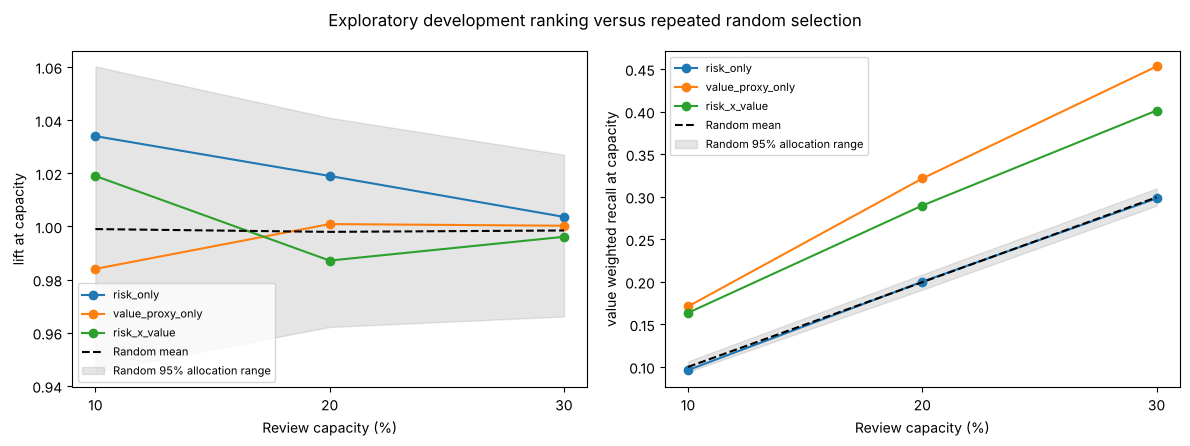

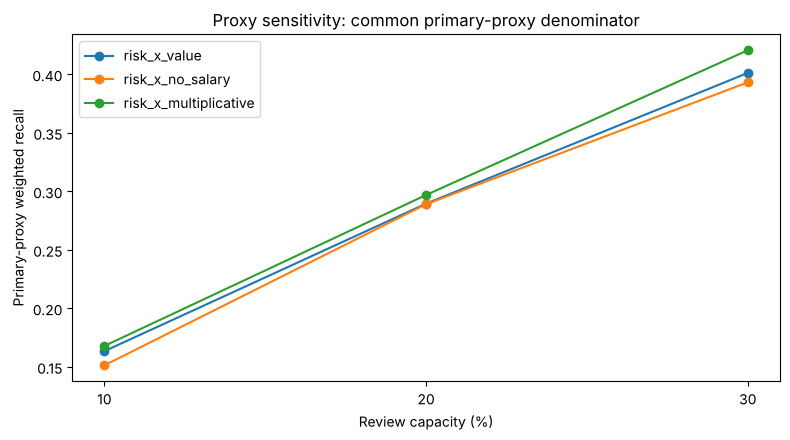

In [6]:
out = ROOT / "results/prioritization"
out.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["lift_at_capacity", "value_weighted_recall_at_capacity"]):
    for strategy in ["risk_only", "value_proxy_only", "risk_x_value"]:
        table = deterministic_summary.loc[deterministic_summary.strategy == strategy].sort_values("capacity")
        ax.plot(table.capacity * 100, table[metric], marker="o", label=strategy)
    baseline = random_intervals.loc[random_intervals.metric == metric].sort_values("capacity")
    ax.plot(baseline.capacity * 100, baseline["mean"], color="black", linestyle="--", label="Random mean")
    ax.fill_between(baseline.capacity * 100, baseline.lower_95, baseline.upper_95,
                    color="gray", alpha=.2, label="Random 95% allocation range")
    ax.set(xlabel="Review capacity (%)", ylabel=metric.replace("_", " "), xticks=[10, 20, 30])
    ax.legend(fontsize=8)
fig.suptitle("Exploratory development ranking versus repeated random selection")
fig.tight_layout()
fig.savefig(out / "figure_01_capacity_comparison.png", dpi=160)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.5))
for strategy in ["risk_x_value", "risk_x_no_salary", "risk_x_multiplicative"]:
    table = deterministic_summary.loc[deterministic_summary.strategy == strategy].sort_values("capacity")
    ax.plot(table.capacity * 100, table.value_weighted_recall_at_capacity, marker="o", label=strategy)
ax.set(xlabel="Review capacity (%)", ylabel="Primary-proxy weighted recall", xticks=[10, 20, 30],
       title="Proxy sensitivity: common primary-proxy denominator")
ax.legend()
fig.tight_layout()
fig.savefig(out / "figure_02_proxy_sensitivity.png", dpi=160)
plt.show()
plt.close(fig)

## 5. Threshold reference and conclusion

The 0.50 threshold strategy can select a very different fraction of employees from a fixed-capacity allocation. Report its actual selection rate; do not compare it as if it reviewed exactly 20%. No threshold is selected or frozen here.

The formal holdout cannot choose capacities, proxy formulas or strategies. These tables support an academic negative-result discussion; raw scores and a synthetic proxy do not establish who should receive an intervention.

In [7]:
threshold_metrics = calculate_binary_metrics(risk.y_true, risk.y_probability, threshold=.50)
threshold_reference = pd.DataFrame([{
    "risk_model": leader, "threshold": .50,
    **{key: threshold_metrics[key] for key in ["predicted_positive_count", "predicted_positive_rate", "precision", "recall", "f1"]},
}])
display(threshold_reference)
primary = deterministic_summary.loc[(deterministic_summary.capacity == .20) &
                                     (deterministic_summary.strategy == "risk_x_value")].iloc[0]
random_lift = random_intervals.loc[(random_intervals.capacity == .20) &
                                  (random_intervals.metric == "lift_at_capacity")].iloc[0]
decision = {
    "status": "exploratory development-only simulation", "risk_model": leader,
    "risk_model_finally_frozen": False, "calibration_used": False, "policy_frozen": False,
    "development_rows": len(risk), "primary_capacity": .20, "sensitivity_capacities": [.10, .30],
    "random_repeats": N_RANDOM_REPEATS, "random_seed": RANDOM_SEED,
    "proxy_normalization": "outer-training development fit; validation transform; clip to [0,1]",
    "multiplicative_epsilon": EPSILON, "formal_holdout_accessed": False,
    "warning": "Academic raw-score simulation only. No operational policy, causal benefit, employee worth or monetary return is established.",
}
display(Markdown(
    f"At 20% capacity, **risk × primary proxy lift = {primary.lift_at_capacity:.4f}**. "
    f"Repeated-random lift has mean {random_lift['mean']:.4f} and an allocation range "
    f"[{random_lift.lower_95:.4f}, {random_lift.upper_95:.4f}]. "
    "Read this alongside value-weighted capture and the near-no-skill AP result. "
    "These descriptive comparisons establish no reliable intervention benefit or final policy."
))

,risk_model,threshold,predicted_positive_count,predicted_positive_rate,precision,recall,f1
0,XGBoost,0.500000,15215,0.190188,0.102662,0.195055,0.134522


At 20% capacity, **risk × primary proxy lift = 0.9871**. Repeated-random lift has mean 0.9979 and an allocation range [0.9621, 1.0408]. Read this alongside value-weighted capture and the near-no-skill AP result. These descriptive comparisons establish no reliable intervention benefit or final policy.

## 6. Export and completion checks

Save aggregate strategy metrics, all repeated-random metrics, their interval summary, normalization bounds, threshold reference and the decision JSON. No employee-level rankings are exported. Verify capacity counts, metric bounds and CSV/JSON round trips.

In [8]:
def save_verified_table(frame, path):
    """Export an aggregate table and verify its values survive the CSV round trip."""
    frame.to_csv(path, index=False)
    saved = pd.read_csv(path)
    pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False,
                                  rtol=1e-10, atol=1e-12)


def save_verified_json(document, path):
    """Reject non-finite JSON values and confirm a readable, exact round trip."""
    path.write_text(json.dumps(document, indent=2, allow_nan=False), encoding="utf-8")
    assert json.loads(path.read_text(encoding="utf-8")) == document

In [9]:
for table, filename in [
    (summary, "prioritization_summary.csv"), (random_repeats, "random_repeats.csv"),
    (random_intervals, "random_baseline_intervals.csv"), (normalization_audit, "proxy_normalization_audit.csv"),
    (threshold_reference, "threshold_reference.csv"),
]:
    save_verified_table(table, out / filename)
save_verified_json(decision, out / "prioritization_decision.json")
assert len(random_repeats) == N_RANDOM_REPEATS * len(CAPACITIES)
for capacity in CAPACITIES:
    assert summary.loc[summary.capacity == capacity, "selected_count"].eq(round(len(risk) * capacity)).all()
    assert random_repeats.loc[random_repeats.capacity == capacity, "selected_count"].eq(round(len(risk) * capacity)).all()
for metric in ["precision_at_capacity", "recall_at_capacity", "value_weighted_recall_at_capacity", "selected_proxy_value_share"]:
    assert summary[metric].between(0, 1).all()
print("Complete: fixed-capacity rankings, proxy sensitivity, 200 random repeats and aggregate exports verified.")
print("No calibrated probability source, operational policy or final holdout result is claimed.")

Complete: fixed-capacity rankings, proxy sensitivity, 200 random repeats and aggregate exports verified.
No calibrated probability source, operational policy or final holdout result is claimed.
